# 02 — Misclassification of ice pellets and freezing rain with lead time

When mPING observes **ice pellets (IP)** or **freezing rain (FZRA)**, what does each forecast system predict, and how does that change from forecast day 1 to day 7?

POD only says how often the class was hit. This notebook shows **where the misses go**: rain, snow, the other freezing class, or (native GFS only) no ptype. The destination class indicates the likely error in the thermal profile:

| Observed → forecast | Likely profile error |
|---|---|
| FZRA → Rain | Surface too warm / surface cold layer lost |
| FZRA or IP → Snow | Elevated warm layer (warm nose) missing or too weak |
| IP → FZRA | Refreezing layer too shallow or too weak |
| FZRA → IP | Refreezing layer too deep or too cold |

**Input:** `common_valid_multimodel_predictions.parquet` from notebook **01** (the same common-valid sample used for CSI, bias, POD and FAR).

**Outputs**

| File | Contents |
|---|---|
| `ip_fzra_fate_by_day.csv` | Fraction forecast as each class, per system / observed class / day |
| `ip_fzra_fate_day1_vs_day7.csv` | Compact day-1 vs day-7 summary for writing the Results text |
| `ip_fzra_fate_by_leadtime.pdf` | Figure: stacked-bar fate plot |

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

pd.set_option("display.max_columns", 100)

## 2. Configuration

Paths and class definitions must match notebook 01. `SYSTEM_ORDER` fixes the model and method order used in the figure.

In [2]:
# ============================================================
# OBSERVED-CLASS RULE (must match notebook 01: "modal" | "consensus")
# ============================================================
OBS_RULE = "modal"
_RULE_SUFFIX = "" if OBS_RULE == "consensus" else f"_{OBS_RULE}"

# ============================================================
# PATHS (must match notebook 01)
# ============================================================
AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
OUT = AI_BASE / f"verification_multimodel{_RULE_SUFFIX}"
FIG = Path("/glade/work/sakor/AI_NWP") / f"figures{_RULE_SUFFIX}"
FIG.mkdir(parents=True, exist_ok=True)

COMMON_FILE = OUT / "common_valid_multimodel_predictions.parquet"

# ============================================================
# CLASSES
# ============================================================
CLASS_NAMES = {0: "Rain", 1: "Snow", 2: "Ice Pellet", 3: "Freezing Rain"}
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
FRZR_IP_CLASSES = ["Ice Pellet", "Freezing Rain"]

NONE_LABEL = "No ptype"                      # native GFS code -1
CODE_TO_NAME = {**CLASS_NAMES, -1: NONE_LABEL}
DEST_ORDER = CLASS_ORDER + [NONE_LABEL]

SYSTEM_ORDER = [
    "Aurora — EDNN", "Aurora — Bourgouin",
    "GraphCast — EDNN", "GraphCast — Bourgouin",
    "WXFormer — EDNN", "WXFormer — Bourgouin",
    "FuXi — EDNN", "FuXi — Bourgouin",
    "Pangu-Weather — EDNN", "Pangu-Weather — Bourgouin",
    "GFS — Native", "GFS — EDNN",
]
MODEL_ORDER = list(dict.fromkeys(s.split(" — ")[0] for s in SYSTEM_ORDER))
OTHER_METHOD = {m: ("Native" if m == "GFS" else "Bourgouin") for m in MODEL_ORDER}

## 3. Load the common-valid sample

The sanity checks confirm that:
- every system is present, and
- every observation/day pair has all 12 systems (i.e. the file is the common-valid sample from notebook 01).

In [3]:
if not COMMON_FILE.exists():
    raise FileNotFoundError(f"{COMMON_FILE} not found — run notebook 01 first.")

common = pd.read_parquet(COMMON_FILE)

assert set(common.System) == set(SYSTEM_ORDER), "system set differs from SYSTEM_ORDER"
assert (common.groupby(["obs_id", "forecast_day"]).System.nunique()
              .eq(len(SYSTEM_ORDER)).all()), "not a common-valid sample"

print(f"Rows: {len(common):,} | obs/day pairs: {common[['obs_id','forecast_day']].drop_duplicates().shape[0]:,}")
print("\nObserved IP / FZRA per forecast day (per system):")
print(common[(common.System == SYSTEM_ORDER[0]) & common.obs_class.isin(FRZR_IP_CLASSES)]
      .groupby(["forecast_day", "obs_class"]).size().unstack())

Rows: 2,566,320 | obs/day pairs: 213,860

Observed IP / FZRA per forecast day (per system):
obs_class     Freezing Rain  Ice Pellet
forecast_day                           
1                      1034        1760
2                      1032        1758
3                      1036        1754
4                      1036        1758
5                      1028        1734
6                      1028        1756
7                      1026        1738


## 4. Fate table (row-normalised confusion matrix)

For each system, observed class (IP or FZRA) and forecast day, this computes the **fraction of cases forecast as each class**.
- The fractions sum to 1 (including "No ptype" for native GFS).
- The fraction for the observed class itself equals the POD in notebook 01.

In [4]:
sub = common[common.obs_class.isin(FRZR_IP_CLASSES)].copy()
sub["pred_class"] = sub.pred_code.map(CODE_TO_NAME)
assert sub.pred_class.notna().all(), "unexpected pred_code values"

fate = (
    sub.groupby(["System", "Model", "Method", "obs_class", "forecast_day"])
       .pred_class.value_counts(normalize=True)
       .unstack(fill_value=0.0)
       .reindex(columns=DEST_ORDER, fill_value=0.0)
       .reset_index()
)

# sample size per observed class and day (identical across systems)
fate_n = sub[sub.System == SYSTEM_ORDER[0]].groupby(["obs_class", "forecast_day"]).size()
fate = fate.merge(fate_n.rename("N").reset_index(), on=["obs_class", "forecast_day"])

assert np.allclose(fate[DEST_ORDER].sum(axis=1), 1.0)
fate.to_csv(OUT / "ip_fzra_fate_by_day.csv", index=False)
fate.head()

,System,Model,Method,obs_class,forecast_day,Rain,Snow,Ice Pellet,Freezing Rain,No ptype,N
0,Aurora — Bourgouin,Aurora,Bourgouin,Freezing Rain,1,0.214700,0.119923,0.143133,0.522244,0.0,1034
1,Aurora — Bourgouin,Aurora,Bourgouin,Freezing Rain,2,0.255814,0.153101,0.139535,0.451550,0.0,1032
2,Aurora — Bourgouin,Aurora,Bourgouin,Freezing Rain,3,0.249035,0.183398,0.158301,0.409266,0.0,1036
3,Aurora — Bourgouin,Aurora,Bourgouin,Freezing Rain,4,0.250965,0.250965,0.146718,0.351351,0.0,1036
4,Aurora — Bourgouin,Aurora,Bourgouin,Freezing Rain,5,0.348249,0.260700,0.071984,0.319066,0.0,1028


## 5. Day-1 vs day-7 summary

This is a compact table for writing the Results text. It shows each system's fractions at the shortest and longest forecast day, plus the change between them (day 7 − day 1).

In [5]:
d17 = (fate[fate.forecast_day.isin([1, 7])]
       .set_index(["obs_class", "System", "forecast_day"])[DEST_ORDER]
       .unstack("forecast_day"))
d17.columns = [f"{dest} d{day}" for dest, day in d17.columns]

for dest in DEST_ORDER:
    d17[f"{dest} Δ"] = d17[f"{dest} d7"] - d17[f"{dest} d1"]

col_order = [f"{d} {s}" for d in DEST_ORDER for s in ("d1", "d7", "Δ")]
d17 = (d17[col_order]
       .reindex(pd.MultiIndex.from_product([FRZR_IP_CLASSES, SYSTEM_ORDER],
                                           names=["obs_class", "System"])))

d17.to_csv(OUT / "ip_fzra_fate_day1_vs_day7.csv")
display(d17.round(2))

Rain d1  Rain d7  Rain Δ  Snow d1  \
obs_class     System                                                         
Ice Pellet    Aurora — EDNN                 0.08     0.26    0.18     0.47   
              Aurora — Bourgouin            0.10     0.28    0.17     0.33   
              GraphCast — EDNN              0.09     0.39    0.29     0.46   
              GraphCast — Bourgouin         0.12     0.41    0.29     0.31   
              WXFormer — EDNN               0.10     0.28    0.18     0.57   
              WXFormer — Bourgouin          0.12     0.31    0.19     0.39   
              FuXi — EDNN                   0.10     0.20    0.10     0.55   
              FuXi — Bourgouin              0.12     0.24    0.13     0.32   
              Pangu-Weather — EDNN          0.07     0.47    0.40     0.52   
              Pangu-Weather — Bourgouin     0.11     0.49    0.38     0.37   
              GFS — Native                  0.08     0.08    0.01     0.22   
              GFS — EDNN                    0.09     0.30    0.20     0.40   
Freezing Rain Aurora — EDNN                 0.23     0.34    0.11     0.20   
              Aurora — Bourgouin            0.21     0.36    0.15     0.12   
              GraphCast — EDNN              0.27     0.32    0.06     0.22   
              GraphCast — Bourgouin         0.24     0.38    0.14     0.14   
              WXFormer — EDNN               0.16     0.27    0.11     0.29   
              WXFormer — Bourgouin          0.15     0.27    0.12     0.17   
              FuXi — EDNN                   0.16     0.14   -0.02     0.25   
              FuXi — Bourgouin              0.14     0.16    0.02     0.13   
              Pangu-Weather — EDNN          0.23     0.39    0.16     0.25   
              Pangu-Weather — Bourgouin     0.23     0.42    0.19     0.15   
              GFS — Native                  0.14     0.09   -0.04     0.08   
              GFS — EDNN                    0.19     0.28    0.09     0.17   

                                         Snow d7  Snow Δ  Ice Pellet d1  \
obs_class     System                                                      
Ice Pellet    Aurora — EDNN                 0.47   -0.00           0.29   
              Aurora — Bourgouin            0.32   -0.01           0.28   
              GraphCast — EDNN              0.53    0.06           0.23   
              GraphCast — Bourgouin         0.39    0.07           0.25   
              WXFormer — EDNN               0.64    0.07           0.20   
              WXFormer — Bourgouin          0.52    0.13           0.24   
              FuXi — EDNN                   0.76    0.22           0.20   
              FuXi — Bourgouin              0.65    0.33           0.31   
              Pangu-Weather — EDNN          0.46   -0.06           0.28   
              Pangu-Weather — Bourgouin     0.38    0.01           0.25   
              GFS — Native                  0.23    0.01           0.40   
              GFS — EDNN                    0.60    0.19           0.42   
Freezing Rain Aurora — EDNN                 0.36    0.16           0.16   
              Aurora — Bourgouin            0.26    0.14           0.14   
              GraphCast — EDNN              0.49    0.26           0.12   
              GraphCast — Bourgouin         0.34    0.20           0.11   
              WXFormer — EDNN               0.62    0.33           0.14   
              WXFormer — Bourgouin          0.49    0.32           0.15   
              FuXi — EDNN                   0.76    0.50           0.12   
              FuXi — Bourgouin              0.64    0.51           0.16   
              Pangu-Weather — EDNN          0.45    0.21           0.18   
              Pangu-Weather — Bourgouin     0.35    0.21           0.14   
              GFS — Native                  0.22    0.14           0.18   
              GFS — EDNN                    0.50    0.33           0.30   

                                         Ice Pellet d7  Ice P

## 6. Figure: fate of observed IP and FZRA with lead time

**Layout**
- Rows are the observed class (IP, FZRA); columns are the driving model.
- Each forecast day has two bars: **EDNN** on the left (solid) and **Bourgouin** (AI models) or **native GFS** on the right (hatched).

**Reading a bar**
- The bottom segment is the correct class, and the black line marks its top, so its height is the **POD**.
- The segments above show where the misses went. Grey "No ptype" appears only for native GFS.
- Fractions are conditional on the observed class and each bar sums to 1.


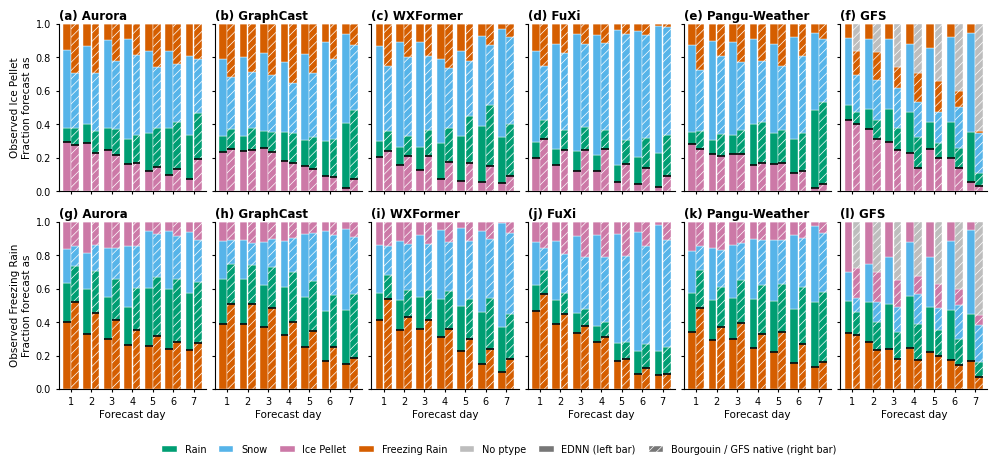

In [6]:
DEST_COLORS = {
    "Rain": "#009E73",
    "Snow": "#56B4E9",
    "Ice Pellet": "#CC79A7",
    "Freezing Rain": "#D55E00",
    NONE_LABEL: "#BDBDBD",
}

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 7.5,
    "axes.titlesize": 8.5, "axes.labelsize": 7.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "hatch.linewidth": 0.5,
})

days = np.arange(1, 8)
W, OFF = 0.38, 0.20            # bar width, offset of each bar from the day tick

fig, axes = plt.subplots(len(FRZR_IP_CLASSES), len(MODEL_ORDER),
                         figsize=(10.0, 4.6), sharex=True, sharey=True)
letters = "abcdefghijklmnop"

for r, obs_cls in enumerate(FRZR_IP_CLASSES):
    stack = [obs_cls] + [d for d in DEST_ORDER if d != obs_cls]   # correct class at bottom
    for c, model in enumerate(MODEL_ORDER):
        ax = axes[r, c]
        for k, method in enumerate(["EDNN", OTHER_METHOD[model]]):
            f = (fate[(fate.Model == model) & (fate.Method == method)
                      & (fate.obs_class == obs_cls)]
                 .set_index("forecast_day").reindex(days))
            x = days + (-OFF if k == 0 else OFF)
            bottom = np.zeros(len(days))
            for dest in stack:
                v = f[dest].to_numpy()
                ax.bar(x, v, W, bottom=bottom, color=DEST_COLORS[dest],
                       hatch=None if k == 0 else "////",
                       edgecolor="white", linewidth=0.3)
                bottom += v
            # black line at top of the correct-class segment (= POD)
            ax.hlines(f[obs_cls].to_numpy(), x - W / 2, x + W / 2,
                      color="black", linewidth=1.2)

        ax.set_ylim(0, 1)
        ax.set_xlim(0.4, 7.6)
        ax.set_xticks(days)
        ax.tick_params(length=2)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        ax.set_title(f"({letters[r * len(MODEL_ORDER) + c]}) {model}",
                     loc="left", fontweight="bold", pad=3)
        if r == len(FRZR_IP_CLASSES) - 1:
            ax.set_xlabel("Forecast day", labelpad=2)
        if c == 0:
            n = fate_n.loc[obs_cls]
            ax.set_ylabel(f"Observed {obs_cls}\n"
                          # f"(N = {n.min():,}–{n.max():,} per day)\n"
                          "Fraction forecast as", labelpad=3)

handles = [Patch(facecolor=DEST_COLORS[d], edgecolor="white", label=d) for d in DEST_ORDER]
handles += [
    Patch(facecolor="#777777", edgecolor="white", label="EDNN (left bar)"),
    Patch(facecolor="#777777", edgecolor="white", hatch="////",
          label="Bourgouin / GFS native (right bar)"),
]
fig.legend(handles=handles, loc="lower center", ncol=len(handles),
           frameon=False, fontsize=7, handlelength=1.6, columnspacing=1.2,
           bbox_to_anchor=(0.5, -0.01))
# fig.text(0.5, -0.045, "Black line = top of correct-class segment (POD). "
#          f"'{NONE_LABEL}' occurs only for GFS native.",
#          ha="center", fontsize=6.5, color="#444444")
fig.tight_layout(rect=(0, 0.06, 1, 1), w_pad=0.6, h_pad=1.0)

fig.savefig(FIG / "ip_fzra_fate_by_leadtime.pdf", dpi=400, bbox_inches="tight")
plt.show()